# Age & Gender Classification from Speech

Predict **age** and **gender** (female / male / child) from audio using a fine-tuned [wav2vec 2.0](https://ai.facebook.com/blog/wav2vec-20-learning-the-structure-of-speech-from-raw-audio/) model.

Model: [w2v2-L-robust-6-age-gender](https://doi.org/10.5281/zenodo.7761387) (6 transformer layers, ONNX)  
License: [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/) (non-commercial)

**Features:**
- Upload your own audio files
- Record audio directly in the notebook
- Instant age & gender prediction with visualization

## 1. Install Dependencies

In [1]:
!pip install -q audonnx audeer audinterface ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.9/74.9 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.7/133.7 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 64.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.0/325.0 kB 24.1 MB/s eta 0:00:00


## 2. Download & Load Model

In [2]:
import os
import audeer
import audonnx
import numpy as np

MODEL_URL = 'https://zenodo.org/record/7761387/files/w2v2-L-robust-6-age-gender.25c844af-1.1.1.zip'
CACHE_DIR = 'cache'
MODEL_DIR = 'model'
SAMPLING_RATE = 16000

audeer.mkdir(CACHE_DIR)

zip_path = os.path.join(CACHE_DIR, 'model.zip')
if not os.path.exists(zip_path):
    audeer.download_url(MODEL_URL, zip_path, verbose=True)
if not os.path.exists(MODEL_DIR):
    audeer.extract_archive(zip_path, MODEL_DIR, verbose=True)

model = audonnx.load(MODEL_DIR)
print('Model loaded.')
print(f'Inputs:  {model.inputs}')
print(f'Outputs: {list(model.outputs.keys())}')

Model loaded.
Inputs:  {'signal': {shape: [1, -1], dtype: tensor(float), transform: None}}
Outputs: ['hidden_states', 'logits_age', 'logits_gender']


## 3. Prediction Helpers

In [3]:
import io
import wave
import struct
import base64
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from IPython.display import display, Audio, HTML, clear_output


def load_audio(path):
    """Load an audio file to a 16 kHz mono float32 numpy array."""
    import subprocess, tempfile
    # Convert any format to 16kHz mono WAV via ffmpeg (available on Kaggle)
    tmp = tempfile.mktemp(suffix='.wav')
    subprocess.run(
        ['ffmpeg', '-y', '-i', path, '-ar', '16000', '-ac', '1', tmp],
        capture_output=True,
    )
    with wave.open(tmp, 'rb') as wf:
        frames = wf.readframes(wf.getnframes())
        signal = np.frombuffer(frames, dtype=np.int16).astype(np.float32) / 32768.0
    os.remove(tmp)
    return signal


def predict(signal):
    """Run the model and return a clean results dict."""
    result = model(signal, SAMPLING_RATE)
    age_score = float(result['logits_age'][0][0])
    age_years = round(age_score * 100, 1)
    gender_logits = result['logits_gender'][0]
    labels = ['female', 'male', 'child']
    gender_idx = int(np.argmax(gender_logits))
    return {
        'age_years': age_years,
        'age_score': age_score,
        'gender': labels[gender_idx],
        'gender_scores': {l: float(gender_logits[i]) for i, l in enumerate(labels)},
    }


def show_results(result, signal=None):
    """Display prediction results with a chart."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), gridspec_kw={'width_ratios': [1, 1.5]})

    # Age gauge
    ax = axes[0]
    age = result['age_years']
    colors = ['#2ecc71' if age < 18 else '#3498db' if age < 60 else '#e67e22']
    ax.barh(['Age'], [age], color=colors, height=0.5, edgecolor='white')
    ax.set_xlim(0, 100)
    ax.set_xlabel('Predicted Age (years)')
    ax.text(age + 2, 0, f'{age:.0f}', va='center', fontsize=16, fontweight='bold')
    ax.set_title('Age Prediction')

    # Gender bar chart
    ax = axes[1]
    scores = result['gender_scores']
    labels = list(scores.keys())
    values = list(scores.values())
    bar_colors = ['#e74c3c', '#3498db', '#2ecc71']
    bars = ax.bar(labels, values, color=bar_colors, edgecolor='white', width=0.6)
    winner = result['gender']
    for bar, label in zip(bars, labels):
        if label == winner:
            bar.set_edgecolor('black')
            bar.set_linewidth(2)
    ax.set_ylabel('Logit Score')
    ax.set_title(f'Gender: {winner.upper()}')
    ax.axhline(0, color='gray', linewidth=0.5)

    plt.tight_layout()
    plt.show()

    if signal is not None:
        display(Audio(signal, rate=SAMPLING_RATE))

print('Helpers ready.')

Helpers ready.


## 4. Quick Test — Random Noise

Verify everything works with a random signal (no real speech, so predictions are meaningless).

Age: 40.2 years | Gender: female


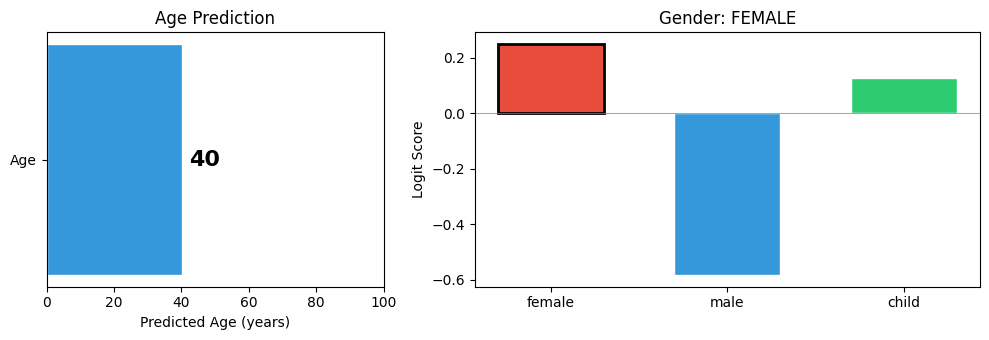

In [4]:
np.random.seed(42)
test_signal = np.random.normal(size=SAMPLING_RATE).astype(np.float32)
result = predict(test_signal)
print(f"Age: {result['age_years']} years | Gender: {result['gender']}")
show_results(result, test_signal)

---
## 5. Upload Audio Files

Upload one or more audio files (WAV, MP3, OGG, FLAC, etc.) and classify each one.

In [5]:
import ipywidgets as widgets
import tempfile

uploader = widgets.FileUpload(accept='audio/*', multiple=True, description='Upload Audio')
output = widgets.Output()


def on_upload(change):
    with output:
        clear_output(wait=True)
        files = change['new']
        if not files:
            return
        for f in files:
            name = f['name'] if isinstance(f, dict) else f.name
            content = f['content'] if isinstance(f, dict) else f.content
            print(f'\n--- {name} ---')
            ext = os.path.splitext(name)[1] or '.wav'
            tmp = tempfile.mktemp(suffix=ext)
            with open(tmp, 'wb') as fp:
                fp.write(content if isinstance(content, bytes) else content.tobytes())
            try:
                signal = load_audio(tmp)
                result = predict(signal)
                print(f"Age: {result['age_years']} years | Gender: {result['gender']}")
                show_results(result, signal)
            except Exception as e:
                print(f'Error processing {name}: {e}')
            finally:
                if os.path.exists(tmp):
                    os.remove(tmp)


uploader.observe(on_upload, names='value')
display(uploader, output)

FileUpload(value=(), accept='audio/*', description='Upload Audio', multiple=True)

Output()

## 6. Record Audio (Browser Microphone)

Click **Start Recording**, speak, then **Stop & Classify**. Works in Kaggle and Jupyter.

In [6]:
RECORD_JS = """
<style>
  .rec-btn {
    padding: 10px 24px; font-size: 15px; border: none; border-radius: 6px;
    cursor: pointer; margin: 4px; color: white;
  }
  .rec-start { background: #e74c3c; }
  .rec-stop  { background: #2c3e50; }
  #rec-status { margin: 8px 0; font-style: italic; color: #555; }
</style>
<div id="rec-container">
  <button class="rec-btn rec-start" onclick="startRec()">🎤 Start Recording</button>
  <button class="rec-btn rec-stop" onclick="stopRec()" disabled id="stop-btn">⏹ Stop & Classify</button>
  <div id="rec-status">Ready</div>
</div>
<script>
var mediaRecorder, audioChunks = [];

async function startRec() {
  audioChunks = [];
  const stream = await navigator.mediaDevices.getUserMedia({audio: true});
  mediaRecorder = new MediaRecorder(stream);
  mediaRecorder.ondataavailable = e => audioChunks.push(e.data);
  mediaRecorder.onstop = async () => {
    stream.getTracks().forEach(t => t.stop());
    const blob = new Blob(audioChunks, {type: 'audio/webm'});
    const reader = new FileReader();
    reader.onloadend = () => {
      const b64 = reader.result.split(',')[1];
      const kernel = Jupyter.notebook ? Jupyter.notebook.kernel
                   : (google && google.colab ? google.colab.kernel : null);
      if (kernel && kernel.execute) {
        kernel.execute('_recorded_b64 = "' + b64 + '"');
        kernel.execute('_process_recording()');
      } else {
        // Kaggle: use IPython.notebook.kernel
        try {
          IPython.notebook.kernel.execute('_recorded_b64 = "' + b64 + '"');
          IPython.notebook.kernel.execute('_process_recording()');
        } catch(e) {
          document.getElementById('rec-status').innerText = 'Error: ' + e;
        }
      }
      document.getElementById('rec-status').innerText = 'Processing...';
    };
    reader.readAsDataURL(blob);
  };
  mediaRecorder.start();
  document.getElementById('rec-status').innerText = 'Recording...';
  document.getElementById('stop-btn').disabled = false;
}

function stopRec() {
  mediaRecorder.stop();
  document.getElementById('stop-btn').disabled = true;
}
</script>
"""


def _process_recording():
    """Called from JS after recording finishes."""
    raw = base64.b64decode(_recorded_b64)
    tmp = tempfile.mktemp(suffix='.webm')
    with open(tmp, 'wb') as f:
        f.write(raw)
    try:
        signal = load_audio(tmp)
        result = predict(signal)
        print(f"\nAge: {result['age_years']} years | Gender: {result['gender']}")
        show_results(result, signal)
    except Exception as e:
        print(f'Error: {e}')
    finally:
        if os.path.exists(tmp):
            os.remove(tmp)


display(HTML(RECORD_JS))

## 7. Classify a File by Path

If you've uploaded files to Kaggle's `/kaggle/input/` or have local audio, specify the path here.

In [7]:
# Change this to your audio file path
AUDIO_PATH = 'your_audio.wav'

if os.path.exists(AUDIO_PATH):
    signal = load_audio(AUDIO_PATH)
    result = predict(signal)
    print(f"File: {AUDIO_PATH}")
    print(f"Age:  {result['age_years']} years")
    print(f"Gender: {result['gender']}")
    print(f"Scores: {result['gender_scores']}")
    show_results(result, signal)
else:
    print(f'File not found: {AUDIO_PATH}')
    print('Update AUDIO_PATH above or use the upload/record cells.')

File not found: your_audio.wav
Update AUDIO_PATH above or use the upload/record cells.


## 8. Batch Classify a Folder

Point this at a directory of audio files to classify all of them at once.

In [8]:
AUDIO_DIR = '/kaggle/input'  # or any directory with audio files
EXTENSIONS = {'.wav', '.mp3', '.ogg', '.flac', '.webm', '.m4a'}

rows = []
if os.path.isdir(AUDIO_DIR):
    audio_files = sorted(
        f for f in os.listdir(AUDIO_DIR)
        if os.path.splitext(f)[1].lower() in EXTENSIONS
    )
    if not audio_files:
        print(f'No audio files found in {AUDIO_DIR}')
    for fname in audio_files:
        path = os.path.join(AUDIO_DIR, fname)
        try:
            signal = load_audio(path)
            r = predict(signal)
            rows.append({
                'file': fname,
                'age': r['age_years'],
                'gender': r['gender'],
                **r['gender_scores'],
            })
            print(f"  {fname:40s}  age={r['age_years']:5.1f}  gender={r['gender']}")
        except Exception as e:
            print(f'  {fname}: ERROR — {e}')
else:
    print(f'Directory not found: {AUDIO_DIR}')
    print('Update AUDIO_DIR above.')

if rows:
    df_results = pd.DataFrame(rows)
    display(df_results)

No audio files found in /kaggle/input


## 9. Visualize Batch Results

In [9]:
if rows:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Age distribution
    ax = axes[0]
    ax.hist(df_results['age'], bins=range(0, 105, 5), color='#3498db', edgecolor='white')
    ax.set_xlabel('Predicted Age (years)')
    ax.set_ylabel('Count')
    ax.set_title('Age Distribution')

    # Gender distribution
    ax = axes[1]
    counts = df_results['gender'].value_counts()
    color_map = {'female': '#e74c3c', 'male': '#3498db', 'child': '#2ecc71'}
    colors = [color_map.get(g, '#95a5a6') for g in counts.index]
    ax.bar(counts.index, counts.values, color=colors, edgecolor='white', width=0.5)
    ax.set_ylabel('Count')
    ax.set_title('Gender Distribution')

    plt.tight_layout()
    plt.show()
else:
    print('No batch results to visualize. Run section 8 first.')

No batch results to visualize. Run section 8 first.


---

### Citation

```bibtex
@inproceedings{Burkhardt2023,
   author = {Felix Burkhardt and Johannes Wagner and Hagen Wierstorf and Florian Eyben and Björn Schuller},
   journal = {15th ITG conference on Speech Communication},
   title = {Speech-based Age and Gender Prediction with Transformers},
   year = {2023},
}
```

Model: [doi:10.5281/zenodo.7761387](https://doi.org/10.5281/zenodo.7761387) | 
Code: [audeering/w2v2-age-gender-how-to](https://github.com/audeering/w2v2-age-gender-how-to)